# Variational Autoencoder (VAE) — PyTorch

**Workflow:**
1. Upload a **training image** → VAE learns its latent representation
2. Upload a **test image** → VAE reconstructs it through the learned latent space
3. Clean visualization of results, loss curve, and random samples

---

## 1 · Imports & Setup

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

print(f"PyTorch  : {torch.__version__}")

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
    
print(f"Device   : {DEVICE}")

PyTorch  : 2.12.0
Device   : mps


## 2 · Configuration
Adjust these hyperparameters as needed.

In [2]:
IMG_SIZE   = 64    # resize all images to this square
LATENT_DIM = 128   # size of the latent vector z
EPOCHS     = 300   # training iterations
LR         = 1e-3  # Adam learning rate

## 3 · Image Utilities

In [3]:
to_tensor = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

def load_image(path: str) -> torch.Tensor:
    """Load an image from disk -> (1, 3, H, W) tensor on DEVICE."""
    img = Image.open(path).convert("RGB")
    return to_tensor(img).unsqueeze(0).to(DEVICE)

def to_numpy(t: torch.Tensor):
    """Convert a (1, 3, H, W) tensor -> (H, W, 3) numpy array for imshow."""
    return t.squeeze(0).permute(1, 2, 0).clamp(0, 1).cpu().detach().numpy()

## 4 · VAE Model

Architecture: **4-layer convolutional encoder → μ / log σ² heads → reparameterize → 4-layer transposed-conv decoder**

In [4]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        ch = [3, 32, 64, 128, 256]

        # Encoder
        enc = []
        for i in range(len(ch) - 1):
            enc += [nn.Conv2d(ch[i], ch[i+1], 4, 2, 1), nn.ReLU()]
        self.encoder = nn.Sequential(*enc)

        flat = ch[-1] * (IMG_SIZE // 2**4) ** 2
        self.fc_mu  = nn.Linear(flat, LATENT_DIM)
        self.fc_var = nn.Linear(flat, LATENT_DIM)

        # Decoder
        self.fc_dec       = nn.Linear(LATENT_DIM, flat)
        self.base_ch      = ch[-1]
        self.base_spatial = IMG_SIZE // 2**4

        dec = []
        for i in range(len(ch) - 1, 0, -1):
            out_ch = ch[i-1] if i > 1 else 3
            act    = nn.ReLU() if i > 1 else nn.Sigmoid()
            dec   += [nn.ConvTranspose2d(ch[i], out_ch, 4, 2, 1), act]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x):
        h = self.encoder(x).flatten(1)
        return self.fc_mu(h), self.fc_var(h)

    def reparameterize(self, mu, logvar):
        std = (0.5 * logvar).exp()
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        h = self.fc_dec(z).view(-1, self.base_ch,
                                self.base_spatial, self.base_spatial)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


model = VAE().to(DEVICE)
total = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {total:,}")
print(model)

Model parameters: 2,957,251
VAE(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
  )
  (fc_mu): Linear(in_features=4096, out_features=128, bias=True)
  (fc_var): Linear(in_features=4096, out_features=128, bias=True)
  (fc_dec): Linear(in_features=128, out_features=4096, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): ConvTranspose2d(32, 3, kernel_size=(4,

## 5 · Loss Function (ELBO)

$$\mathcal{L} = \underbrace{\|x - \hat{x}\|^2}_{\text{Reconstruction}} + \underbrace{D_{KL}(q(z|x) \| p(z))}_{\text{KL Divergence}}$$

In [5]:
def vae_loss(recon, x, mu, logvar):
    recon_loss = F.mse_loss(recon, x, reduction="sum")
    kld        = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kld

## 6 · Load Training Image
Set `TRAIN_IMAGE` to the path of the image you want the VAE to learn from.

Training tensor shape: torch.Size([1, 3, 64, 64])


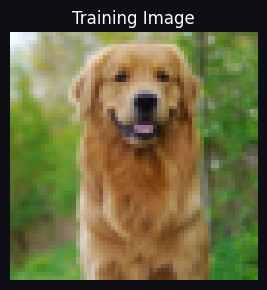

In [6]:
TRAIN_IMAGE = "/Users/macminhanh/Documents/UChicago/Machine Learning II/Assignment 7/train.jpeg"   # <- change to your image path

x_train = load_image(TRAIN_IMAGE)
print(f"Training tensor shape: {x_train.shape}")

plt.figure(figsize=(3, 3), facecolor="#0e0e14")
plt.imshow(to_numpy(x_train))
plt.title("Training Image", color="white", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

## 7 · Train the VAE

In [7]:
opt    = Adam(model.parameters(), lr=LR)
losses = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    opt.zero_grad()
    recon, mu, logvar = model(x_train)
    loss = vae_loss(recon, x_train, mu, logvar)
    loss.backward()
    opt.step()
    losses.append(loss.item())

    if epoch % 50 == 0 or epoch == 1:
        print(f"  Epoch {epoch:>4}/{EPOCHS}   Loss: {loss.item():.1f}")

print("\nTraining complete.")

  Epoch    1/300   Loss: 516.3
  Epoch   50/300   Loss: 228.4
  Epoch  100/300   Loss: 125.3
  Epoch  150/300   Loss: 61.2
  Epoch  200/300   Loss: 29.6
  Epoch  250/300   Loss: 45.5
  Epoch  300/300   Loss: 23.0

Training complete.


## 8 · Load Test Image & Reconstruct
Set `TEST_IMAGE` to any image you want the trained VAE to reconstruct.

In [8]:
TEST_IMAGE = '/Users/macminhanh/Documents/UChicago/Machine Learning II/Assignment 7/test.jpeg'  # <- change to your image path

x_test = load_image(TEST_IMAGE)
print(f"Test tensor shape: {x_test.shape}")

model.eval()
with torch.no_grad():
    recon, _, _ = model(x_test)
    z_rand  = torch.randn(16, LATENT_DIM, device=DEVICE)
    samples = model.decode(z_rand)

print("Reconstruction done.")

Test tensor shape: torch.Size([1, 3, 64, 64])
Reconstruction done.


## 9 · Visualization

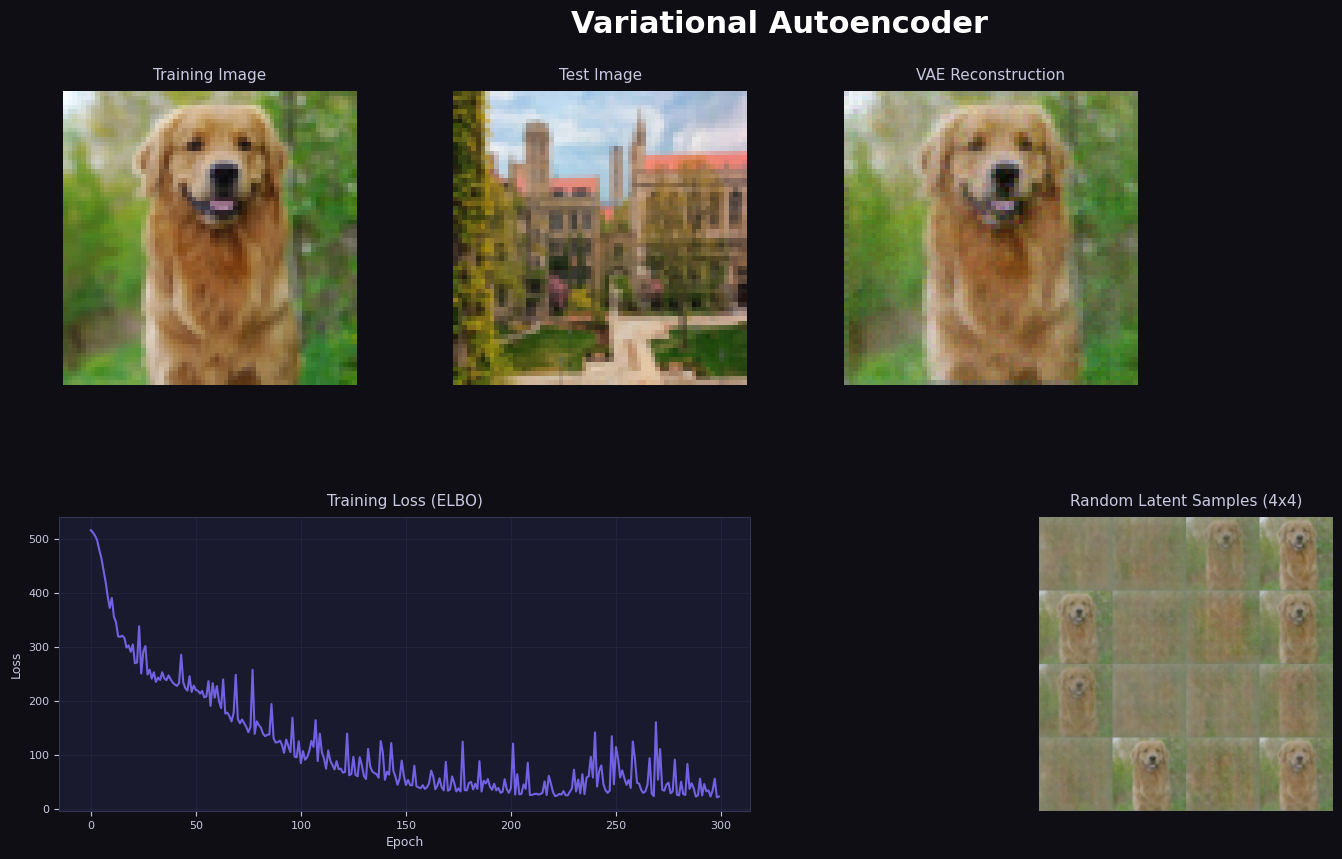

Visualization complete.


In [9]:
fig = plt.figure(figsize=(16, 9), facecolor="#0e0e14")
fig.suptitle("Variational Autoencoder", fontsize=22, color="white",
             fontweight="bold", y=0.97)

axes_color = "#1a1a2e"
text_color = "#c8c8e0"
accent     = "#7c6af7"

grid = fig.add_gridspec(2, 4, hspace=0.45, wspace=0.3,
                        left=0.05, right=0.97, top=0.88, bottom=0.08)

def styled_ax(ax, title):
    ax.set_facecolor(axes_color)
    ax.set_title(title, color=text_color, fontsize=11, pad=8)
    ax.tick_params(colors=text_color, labelsize=8)
    for sp in ax.spines.values():
        sp.set_color("#333355")
    return ax

# Panel 1: Training image
ax1 = styled_ax(fig.add_subplot(grid[0, 0]), "Training Image")
ax1.imshow(to_numpy(x_train)); ax1.axis("off")

# Panel 2: Test image
ax2 = styled_ax(fig.add_subplot(grid[0, 1]), "Test Image")
ax2.imshow(to_numpy(x_test)); ax2.axis("off")

# Panel 3: Reconstruction
ax3 = styled_ax(fig.add_subplot(grid[0, 2]), "VAE Reconstruction")
ax3.imshow(to_numpy(recon)); ax3.axis("off")

# Panel 4: Training loss
ax5 = styled_ax(fig.add_subplot(grid[1, :2]), "Training Loss (ELBO)")
ax5.plot(losses, color=accent, linewidth=1.5, alpha=0.9)
ax5.set_xlabel("Epoch", color=text_color, fontsize=9)
ax5.set_ylabel("Loss",  color=text_color, fontsize=9)
ax5.grid(color="#333355", alpha=0.5, linewidth=0.5)

# Panel 5: Random latent samples (4x4)
ax6 = styled_ax(fig.add_subplot(grid[1, 2:]), "Random Latent Samples (4x4)")
ax6.axis("off")
rows, cols = 4, 4
samples_np = [to_numpy(samples[i]) for i in range(rows * cols)]
grid_img   = np.concatenate(
    [np.concatenate(samples_np[r*cols:(r+1)*cols], axis=1) for r in range(rows)],
    axis=0
)
ax6.imshow(grid_img)

plt.show()
print("Visualization complete.")

#### **Write-ups**

Training image: A golden retriever 
Test image: A UChicago building 
VAE Reconstruction: A golden retriever
Random Latent Samples: All look like variations of the dog

The VAE reconstruction of the test image (a building) looks almost identical to the training image (a golden retriever), rather than resembling the building at all. The output is a blurry, slightly distorted version of the dog.

The VAE was trained exclusively on the dog image, so its encoder and decoder only learned the latent space representation of that one image. When the test image (the building) is passed through the encoder, the model maps it to the closest point it knows in its learned latent space, which is centered around the dog's features (warm brown tones, rounded shapes, green background). 

The decoder then reconstructs from that point, producing a dog-like image regardless of the input. This demonstrates a core limitation of VAEs trained on a single image. The model has no knowledge of any visual features outside its training distribution, so it cannot meaningfully reconstruct out-of-distribution inputs.

loss dropped from 516 to 23 over 300 epochs. This is a well-trained model. The spikes in the curve are normal for single-image training with KL divergence.